In [1]:
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import detection_utils

sys.path.append("../PG_PyTraining")
from common.pg import pg_geometry

%load_ext autoreload
%autoreload 2

In [2]:
def get_center(corners):
    return np.mean(corners, axis=0).astype(int)

def moving_average(x, w):
    return np.convolve(x, np.ones(w), 'valid') / w

def weighted_moving_average(x,y,step_size=0.05,width=1):
    bin_centers = np.arange(np.min(x),np.max(x)-0.5*step_size,step_size)+0.5*step_size
    bin_avg = np.zeros(len(bin_centers))

    def gaussian(x,amp=1,mean=0,sigma=1):
        return amp*np.exp(-(x-mean)**2/(2*sigma**2))

    for index in range(0,len(bin_centers)):
        bin_center = bin_centers[index]
        weights = gaussian(x,mean=bin_center,sigma=width)
        bin_avg[index] = np.average(y,weights=weights)

    return (bin_centers,bin_avg)

In [3]:
frames = []

cap = cv2.VideoCapture("2024-08-19-11-49-25/video01.avi")
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))

cap.release()
len(frames)

1220

In [4]:
detector = detection_utils.ArucoDetector()

In [5]:
tmp = []
for frame in tqdm(frames):
    ids, _ = detector.detect(frame)
    if len(ids) != 5:
        continue
    tmp.append(frame)

len(tmp)

  0%|          | 0/1220 [00:00<?, ?it/s]

100%|██████████| 1220/1220 [00:02<00:00, 428.43it/s]


1021

In [6]:
frames = tmp

In [7]:
frame_size = (frames[0].shape[1], frames[0].shape[0])

# Initialize the video writer
fourcc = cv2.VideoWriter_fourcc(*'XVID')
out = cv2.VideoWriter("exp2.avi", fourcc, 5, frame_size)

for i, frame in enumerate(frames):
    tmp_frame = cv2.cvtColor(frame, cv2.COLOR_GRAY2BGR)
    # Overlay the frame index on the frame
    text = f"{i}"
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1
    color = (255, 255, 255)  # White color
    thickness = 2
    # Get text size to create a black background
    text_size = cv2.getTextSize(text, font, font_scale, thickness)[0]
    text_x = 10
    text_y = 10 + text_size[1]
    cv2.rectangle(tmp_frame, (text_x - 5, text_y - text_size[1] - 5), 
                    (text_x + text_size[0] + 5, text_y + 5), 
                    (0, 0, 0), -1)  # Black background
    cv2.putText(tmp_frame, text, (text_x, text_y), font, font_scale, color, thickness)

    # Write the frame to the video file
    out.write(tmp_frame)

out.release()

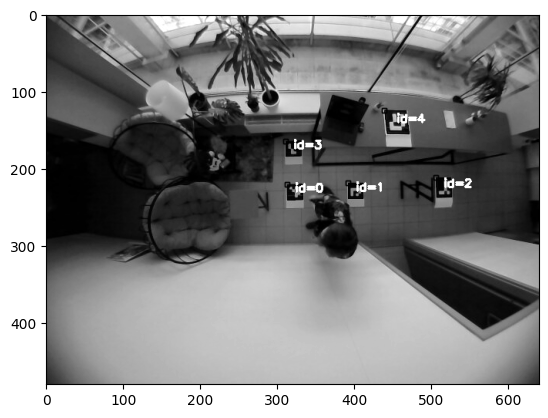

In [8]:
img_gray = frames[0]
corners, ids = detector.detect(img_gray)
len(ids)

tmp = img_gray.copy()
cv2.aruco.drawDetectedMarkers(tmp, corners, ids)
cv2.aruco.drawDetectedMarkers(tmp, corners, ids)
plt.imshow(tmp, cmap="gray")

In [26]:
gt_x_pos = [0, 100, 200, 0, 110]
gt_y_pos = [0, 0, 0, 75, 60]
gt_z_pos = [0, 0, 75, 0, 110]

# gt_z_pos = [0, 0, 65, 0, 100]

In [40]:
cams = [pg_geometry.PgCamera(2650 - i * 10, "Cam3") for i in gt_z_pos]

cams_5 = [pg_geometry.PgCamera(2650 - i * 10 + 50, "Cam3") for i in gt_z_pos]
cams_10 = [pg_geometry.PgCamera(2650 - i * 10 + 100, "Cam3") for i in gt_z_pos]
cams_5_neg = [pg_geometry.PgCamera(2650 - i * 10 - 50, "Cam3") for i in gt_z_pos]
cams_10_neg = [pg_geometry.PgCamera(2650 - i * 10 - 100, "Cam3") for i in gt_z_pos]

In [41]:
data = []
for frame in tqdm(frames):
    # ids, corners, tvecs, rvecs, euler_rvecs = detector.estimate(tmp_frame)
    data.append(detector.estimate(frame))
    

ids, corners, tvecs, rvecs, euler_rvecs = list(zip(*data))
# pos_vecs = np.array([cam.pixel2cm(np.mean(i, axis=(1, 2)).astype(int)) for i in corners])
corners = np.array(corners)
pos_vecs = np.stack(np.array([cams[i].pixel2cm(np.mean(corners[:, i, :, :, :], axis=(1, 2)).astype(int)) for i in range(5)]), axis=1)

pos_vecs_5 = np.stack(np.array([cams_5[i].pixel2cm(np.mean(corners[:, i, :, :, :], axis=(1, 2)).astype(int)) for i in range(5)]), axis=1)
pos_vecs_10 = np.stack(np.array([cams_10[i].pixel2cm(np.mean(corners[:, i, :, :, :], axis=(1, 2)).astype(int)) for i in range(5)]), axis=1)
pos_vecs_5_neg = np.stack(np.array([cams_5_neg[i].pixel2cm(np.mean(corners[:, i, :, :, :], axis=(1, 2)).astype(int)) for i in range(5)]), axis=1)
pos_vecs_10_neg = np.stack(np.array([cams_10_neg[i].pixel2cm(np.mean(corners[:, i, :, :, :], axis=(1, 2)).astype(int)) for i in range(5)]), axis=1)

euler_rvecs = np.array(euler_rvecs)

baseline_euler_rvecs = euler_rvecs[:, 0, :]

# fix roll
baseline_euler_rvecs[:, 0] = np.sign(baseline_euler_rvecs[:, 0]) * (180 - np.abs(baseline_euler_rvecs[:, 0]))

  0%|          | 0/1021 [00:00<?, ?it/s]

100%|██████████| 1021/1021 [00:02<00:00, 348.27it/s]


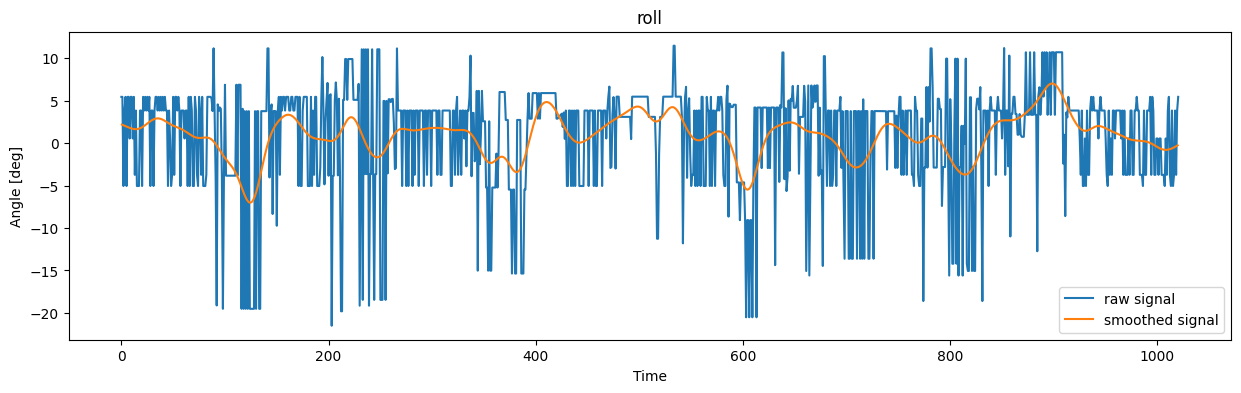

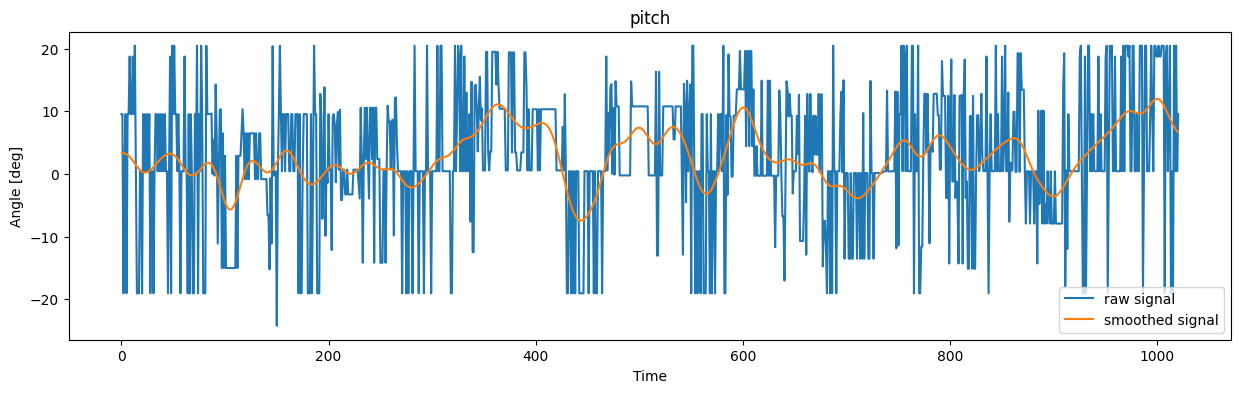

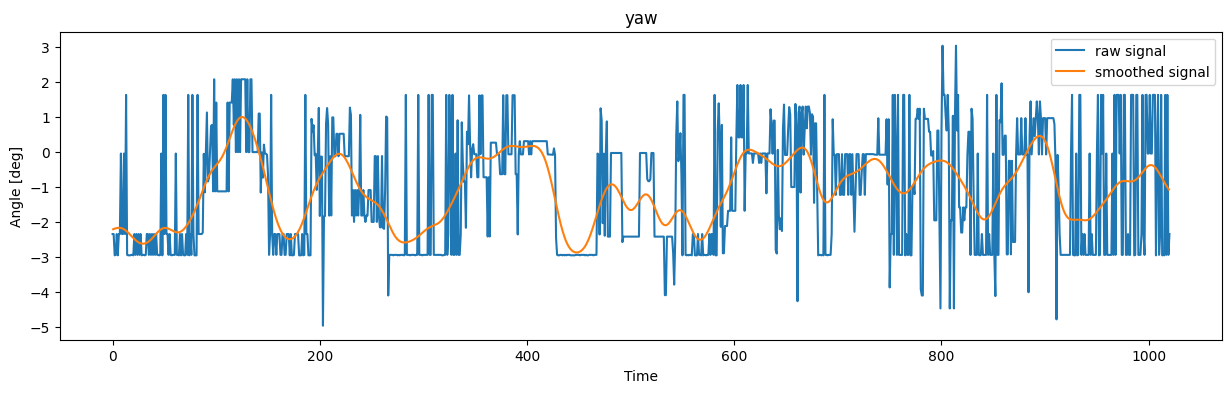

In [42]:
x_axis = np.arange(len(pos_vecs))


labels = ["roll", "pitch", "yaw"]
smoothed_rvecs = []
for i in range(3):
    x, y = weighted_moving_average(x_axis, baseline_euler_rvecs[:, i], step_size=1, width=9)
    smoothed_rvecs.append(y)

    plt.figure(figsize=(15, 4))
    plt.plot(x_axis, baseline_euler_rvecs[:,i], label="raw signal")
    plt.plot(x, y, label="smoothed signal")
    plt.legend()
    plt.xlabel("Time")
    plt.ylabel("Angle [deg]")
    plt.title(labels[i])

smoothed_rvecs = np.vstack(smoothed_rvecs).T

Text(0.5, 1.0, 'Markers position')

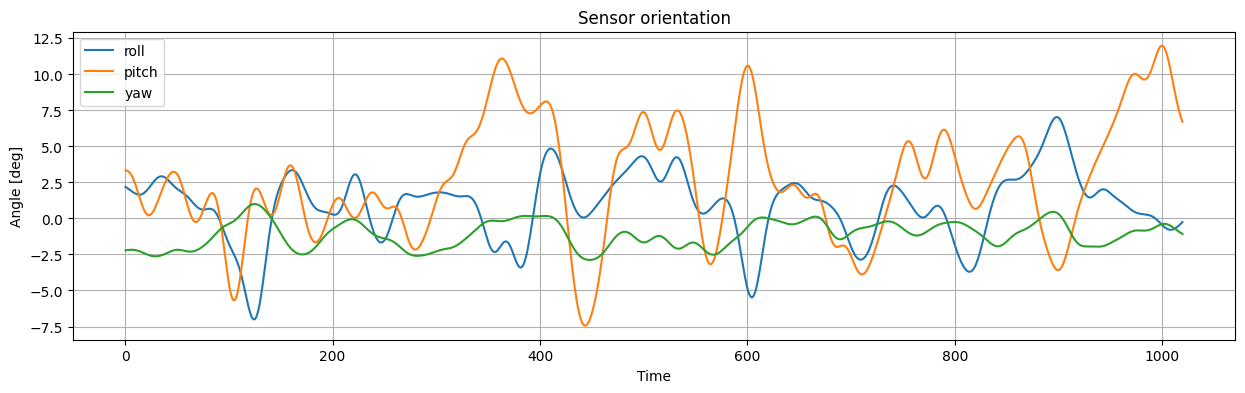

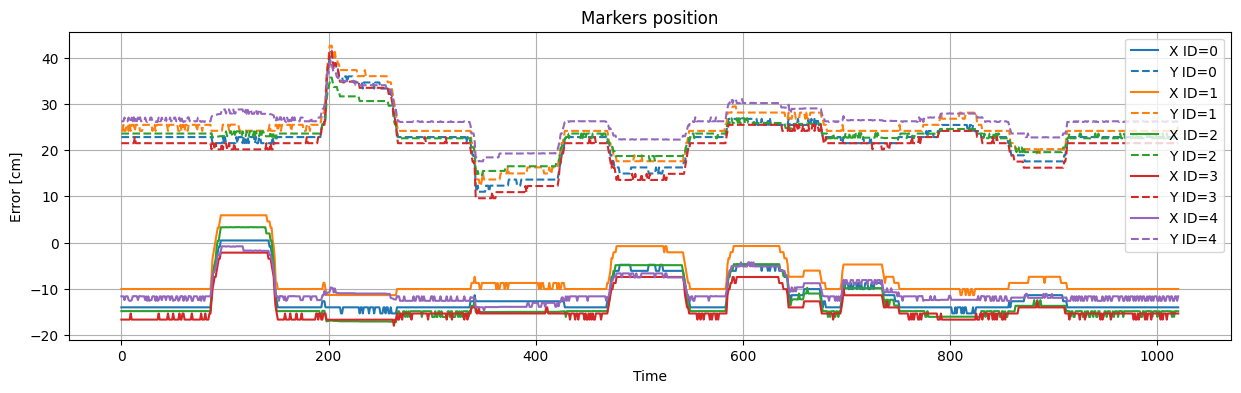

In [49]:
plt.figure(figsize=(15, 4))
for i in range(3):

    plt.plot(x, smoothed_rvecs[:,i], label=labels[i])

plt.legend()
plt.grid()
plt.xlabel("Time")
plt.ylabel("Angle [deg]")
plt.title("Sensor orientation")


plt.figure(figsize=(15, 4))

colors = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red",
    "tab:purple"
]

for i in range(5):
    
    plt.plot(x_axis, -(gt_x_pos[i] - pos_vecs[:, i, 0]), c=colors[i], label=f"X ID={i}")
    plt.plot(x_axis, -(gt_y_pos[i] - pos_vecs[:, i, 1]), "--",c=colors[i], label=f"Y ID={i}")


plt.legend()
plt.grid()
plt.xlabel("Time")
plt.ylabel("Error [cm]")
plt.title("Markers position")


In [44]:
np.corrcoef(pos_vecs[:-1, 0, 0], smoothed_rvecs[:, 0])[0, 1], \
    np.corrcoef(pos_vecs[:-1, 0, 0], smoothed_rvecs[:, 1])[0, 1], \
    np.corrcoef(pos_vecs[:-1, 0, 0], smoothed_rvecs[:, 2])[0, 1]

(-0.26470834028956175, -0.020151403269089967, 0.4427633608440528)

In [45]:
np.corrcoef(pos_vecs[:-1, 0, 1], smoothed_rvecs[:, 0])[0, 1], \
    np.corrcoef(pos_vecs[:-1, 0, 1], smoothed_rvecs[:, 1])[0, 1], \
    np.corrcoef(pos_vecs[:-1, 0, 1], smoothed_rvecs[:, 2])[0, 1]

(-0.2000714609582889, -0.28894421448443364, -0.0963089944805537)

/tmp/ipykernel_184970/194542951.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


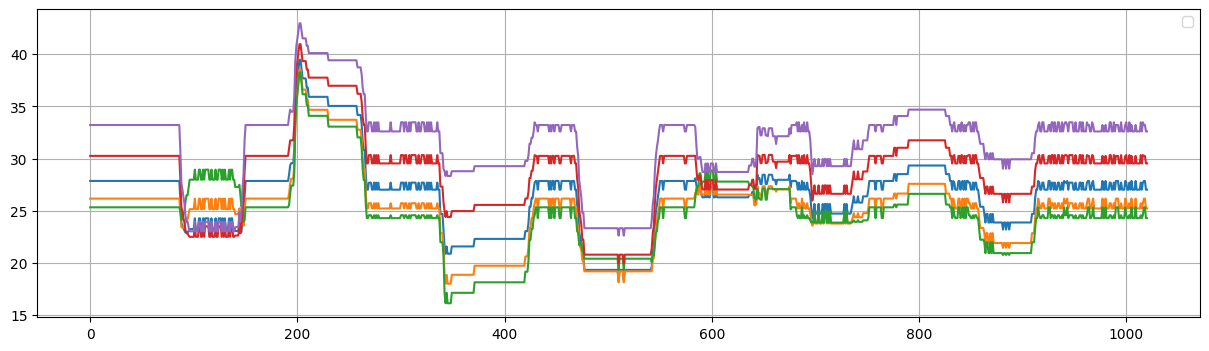

In [62]:
i = 2

lines = []
for j in [pos_vecs, pos_vecs_5, pos_vecs_10, pos_vecs_5_neg, pos_vecs_10_neg]:
    lines.append(np.linalg.norm(np.stack([-(gt_x_pos[i] - j[:, i, 0]), -(gt_y_pos[i] - j[:, i, 1])]).T, axis=1))

plt.figure(figsize=(15, 4))
for line in lines:
    plt.plot(x_axis, line)

plt.legend()
plt.grid()

/tmp/ipykernel_184970/3567163368.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


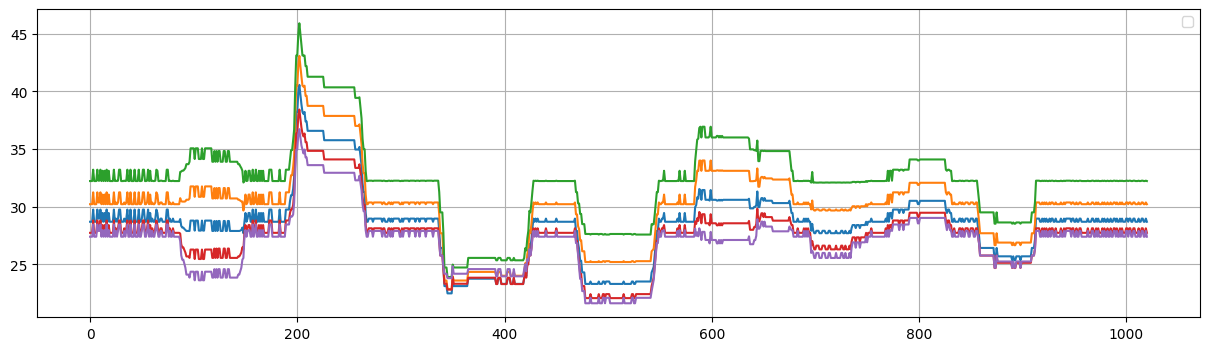

In [63]:
i = 4

lines = []
for j in [pos_vecs, pos_vecs_5, pos_vecs_10, pos_vecs_5_neg, pos_vecs_10_neg]:
    lines.append(np.linalg.norm(np.stack([-(gt_x_pos[i] - j[:, i, 0]), -(gt_y_pos[i] - j[:, i, 1])]).T, axis=1))

plt.figure(figsize=(15, 4))
for line in lines:
    plt.plot(x_axis, line)

plt.legend()
plt.grid()